# Chapter 6: Advanced Logistic Regression and Extensions

## 1. Ringkasan Bab
Regresi logistik merupakan metode statistik fundamental yang sangat populer untuk memecahkan persoalan klasifikasi. Berbeda dengan regresi linier yang memprediksi nilai kontinu, regresi logistik memprediksi probabilitas suatu observasi masuk ke dalam kategori tertentu dengan membatasi output pada rentang $[0, 1]$ melalui fungsi sigmoid atau softmax.

Topik utama yang dibahas pada bab ini meliputi:
- **Prinsip Dasar Regresi Logistik**: Fungsi logistik (sigmoid), estimasi kemungkinan maksimum (Maximum Likelihood Estimation / MLE), serta konsep rasio peluang logaritmik (*log-odds*).
- **Klasifikasi Multikelas**: Pendekatan *One-vs-Rest* (OvR) dengan melatih pengklasifikasi biner terpisah per kelas, serta regresi logistik multinomial (*Softmax Regression*) yang memodelkan distribusi probabilitas seluruh kelas secara simultan.
- **Regularisasi pada Regresi Logistik**: Penerapan penalti Ridge (L2) dan Lasso (L1) untuk mencegah overfitting, serta pengaruh parameter invers regularisasi ($C$) terhadap penyusutan koefisien bobot fitur.
- **Klasifikasi Multilabel**: Penanganan skenario saat satu sampel data dapat memiliki lebih dari satu label kelas secara bersamaan, lengkap dengan analisis matriks kemunculan bersama (*label co-occurrence*).
- **Evaluasi Model Klasifikasi**: Pengukuran kinerja menggunakan akurasi, presisi, recall, F1-score, matriks kebingungan (*confusion matrix*), serta kurva karakteristik operasi penerima (*Receiver Operating Characteristic* / ROC) dan nilai Area Under the Curve (AUC).

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer, load_iris, make_multilabel_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    precision_score, recall_score, f1_score, roc_curve, auc
)
import warnings

# Pengaturan random seed dan penekanan pesan peringatan
np.random.seed(2024)
warnings.filterwarnings('ignore')

print("Pustaka dan dependensi Chapter 6 berhasil dimuat.")

Pustaka dan dependensi Chapter 6 berhasil dimuat.


## 2. Fondasi Teori Regresi Logistik Biner

Pada masalah klasifikasi biner dengan label target $Y \in \{0, 1\}$, regresi logistik memodelkan probabilitas kondisional $P(Y = 1 \mid \mathbf{X})$ menggunakan fungsi logistik standar:
$$P(Y = 1 \mid \mathbf{X}) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 X_1 + \dots + \beta_p X_p)}} = \frac{1}{1 + e^{-\mathbf{X}\boldsymbol{eta}}}$$

Bentuk linier diperoleh melalui transformasi logit atau log-odds:
$$\log\left(\frac{P(Y = 1 \mid \mathbf{X})}{1 - P(Y = 1 \mid \mathbf{X})}\right) = \beta_0 + \beta_1 X_1 + \dots + \beta_p X_p$$

Probabilitas yang dihasilkan kemudian dibandingkan dengan nilai ambang batas (*threshold*, umumnya 0.5) untuk menentukan kelas prediksi akhir. Parameter diestimasi secara numerik menggunakan metode Maximum Likelihood Estimation (MLE).

In [3]:
# Memuat dataset Breast Cancer (Klasifikasi Biner: Malignant vs Benign)
cancer_data = load_breast_cancer()
X_cancer = cancer_data.data
y_cancer = cancer_data.target
cancer_feature_names = cancer_data.feature_names
cancer_target_names = cancer_data.target_names

# Pembagian data latih dan uji (rasio 70:30)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cancer, y_cancer, test_size=0.3, random_state=2024
)

# Standarisasi fitur data
scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)

# Melatih model regresi logistik dasar
log_reg_basic = LogisticRegression(solver='liblinear', random_state=2024)
log_reg_basic.fit(X_train_c_scaled, y_train_c)

# Prediksi kelas dan evaluasi akurasi
y_pred_basic = log_reg_basic.predict(X_test_c_scaled)
acc_basic = accuracy_score(y_test_c, y_pred_basic)

print(f"Dimensi data latih: {X_train_c.shape}, data uji: {X_test_c.shape}")
print(f"Akurasi Regresi Logistik Dasar: {acc_basic:.4f} ({acc_basic * 100:.2f}%)")

Dimensi data latih: (398, 30), data uji: (171, 30)
Akurasi Regresi Logistik Dasar: 0.9825 (98.25%)


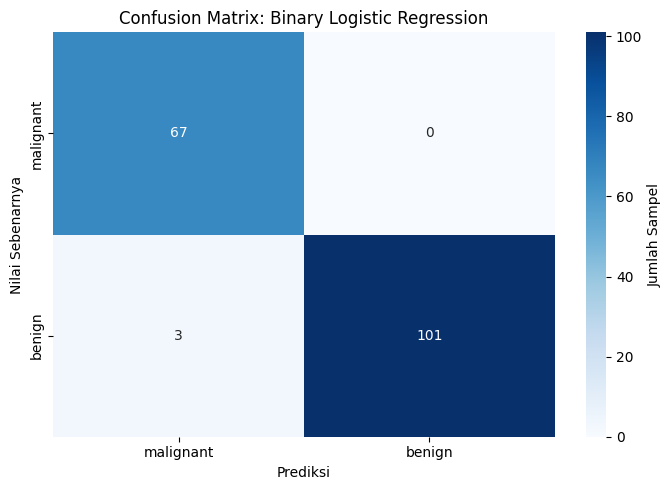

Classification Report:


,precision,recall,f1-score,support
malignant,0.957,1.000,0.978,67
benign,1.000,0.971,0.985,104
accuracy,0.982,0.982,0.982,1
macro avg,0.979,0.986,0.982,171
weighted avg,0.983,0.982,0.983,171


In [4]:
# Visualisasi Confusion Matrix untuk Regresi Logistik Biner
cm_basic = confusion_matrix(y_test_c, y_pred_basic)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_basic,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=cancer_target_names,
    yticklabels=cancer_target_names,
    cbar_kws={'label': 'Jumlah Sampel'}
)
plt.title('Confusion Matrix: Binary Logistic Regression', fontsize=12)
plt.xlabel('Prediksi')
plt.ylabel('Nilai Sebenarnya')
plt.tight_layout()
plt.show()

# Laporan Klasifikasi Rinci
report_dict_basic = classification_report(
    y_test_c, y_pred_basic, target_names=cancer_target_names, output_dict=True
)
df_report_basic = pd.DataFrame(report_dict_basic).transpose()
print("Classification Report:")
display(df_report_basic.style.background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score']).format({
    'precision': '{:.3f}',
    'recall': '{:.3f}',
    'f1-score': '{:.3f}',
    'support': '{:.0f}'
}))

## 3. Strategi Klasifikasi Multikelas: One-vs-Rest (OvR) vs Multinomial

Saat label kategori berjumlah lebih dari dua ($C > 2$), regresi logistik dapat diadaptasi melalui dua pendekatan:

1. **One-vs-Rest (OvR / One-vs-All)**:
   Melatih sebanyak $C$ model pengklasifikasi biner terpisah. Untuk model ke-$k$, sampel kelas $k$ dianggap sebagai kelas positif, sedangkan sampel dari kelas lainnya dikelompokkan menjadi kelas negatif. Prediksi akhir ditentukan oleh model biner yang menghasilkan skor probabilitas tertinggi.

2. **Multinomial Logistic Regression (Softmax Regression)**:
   Mengestimasi probabilitas keanggotaan seluruh kelas secara simultan menggunakan fungsi normalisasi eksponensial (Softmax):
   $$P(Y = k \mid \mathbf{X}) = \frac{e^{\mathbf{X}\boldsymbol{eta}_k}}{\sum_{j=1}^{C} e^{\mathbf{X}\boldsymbol{eta}_j}}$$
   Pendekatan ini sangat tepat jika kelas-kelas target bersifat saling lepas (*mutually exclusive*).

In [5]:
# Memuat dataset Iris (3 Kelas Multikelas)
iris = load_iris()
X_iris = iris.data
y_iris = iris.target
iris_feature_names = iris.feature_names
iris_target_names = iris.target_names

X_tr_iris, X_te_iris, y_tr_iris, y_te_iris = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=2024
)

# 1. Model One-vs-Rest (OvR)
ovr_model = LogisticRegression(multi_class='ovr', solver='liblinear', random_state=2024)
ovr_model.fit(X_tr_iris, y_tr_iris)
y_pred_ovr = ovr_model.predict(X_te_iris)

# 2. Model Multinomial (Softmax)
multinomial_model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000, random_state=2024)
multinomial_model.fit(X_tr_iris, y_tr_iris)
y_pred_multinomial = multinomial_model.predict(X_te_iris)

# Komparasi Akurasi
print(f"Akurasi Model One-vs-Rest (OvR)   : {accuracy_score(y_te_iris, y_pred_ovr):.4f}")
print(f"Akurasi Model Multinomial (Softmax): {accuracy_score(y_te_iris, y_pred_multinomial):.4f}")

# Laporan Klasifikasi Multinomial
df_report_multi = pd.DataFrame(
    classification_report(y_te_iris, y_pred_multinomial, target_names=iris_target_names, output_dict=True)
).transpose()
print("\nClassification Report (Multinomial Logistic Regression):")
display(df_report_multi.style.background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score']).format({
    'precision': '{:.3f}',
    'recall': '{:.3f}',
    'f1-score': '{:.3f}',
    'support': '{:.0f}'
}))

Akurasi Model One-vs-Rest (OvR)   : 0.9556
Akurasi Model Multinomial (Softmax): 0.9333

Classification Report (Multinomial Logistic Regression):


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,18
versicolor,0.846,0.917,0.880,12
virginica,0.929,0.867,0.897,15
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.928,0.926,45
weighted avg,0.935,0.933,0.934,45


## 4. Regularisasi pada Regresi Logistik (L1 vs L2)

Regularisasi ditambahkan ke fungsi kerugian untuk mengurangi risiko overfitting dan mengendalikan kompleksitas model.

1. **Ridge Regularization (L2)**:
   Menambahkan penalti kuadrat koefisien ($\lambda \sum \beta_j^2$). Menyusutkan nilai bobot mendekati nol secara proporsional tanpa mengeliminasinya.
2. **Lasso Regularization (L1)**:
   Menambahkan penalti nilai absolut koefisien ($\lambda \sum \vert{}\beta_j\vert{}$). Mampu memaksa sebagian koefisien tepat bernilai nol untuk seleksi fitur otomatis.

Pada kelas `LogisticRegression` scikit-learn, kekuatan regularisasi dikontrol oleh hyperparameter $C$, yang merupakan invers dari penalti ($C = \frac{1}{\lambda}$):
- Nilai $C$ yang lebih kecil menandakan regularisasi yang lebih kuat (penyusutan koefisien semakin drastis).
- Nilai $C$ yang besar membuat model berperilaku menyerupai regresi logistik standar tanpa batasan penalti.

In [6]:
# Melatih Regresi Logistik dengan Regularisasi L1 (Lasso) dan L2 (Ridge)
ridge_clf = LogisticRegression(penalty='l2', solver='liblinear', C=0.1, random_state=2024)
ridge_clf.fit(X_train_c_scaled, y_train_c)
y_pred_ridge = ridge_clf.predict(X_test_c_scaled)

lasso_clf = LogisticRegression(penalty='l1', solver='liblinear', C=0.1, random_state=2024)
lasso_clf.fit(X_train_c_scaled, y_train_c)
y_pred_lasso = lasso_clf.predict(X_test_c_scaled)

print("=== Perbandingan Model Ter-regularisasi (C=0.1) ===")
print(f"Akurasi Ridge (L2): {accuracy_score(y_test_c, y_pred_ridge):.4f}")
print(f"Akurasi Lasso (L1): {accuracy_score(y_test_c, y_pred_lasso):.4f}")
print(f"Jumlah Fitur Aktif Lasso (L1): {np.sum(lasso_clf.coef_[0] != 0)} dari {X_train_c.shape[1]} fitur")

=== Perbandingan Model Ter-regularisasi (C=0.1) ===
Akurasi Ridge (L2): 0.9825
Akurasi Lasso (L1): 0.9649
Jumlah Fitur Aktif Lasso (L1): 7 dari 30 fitur


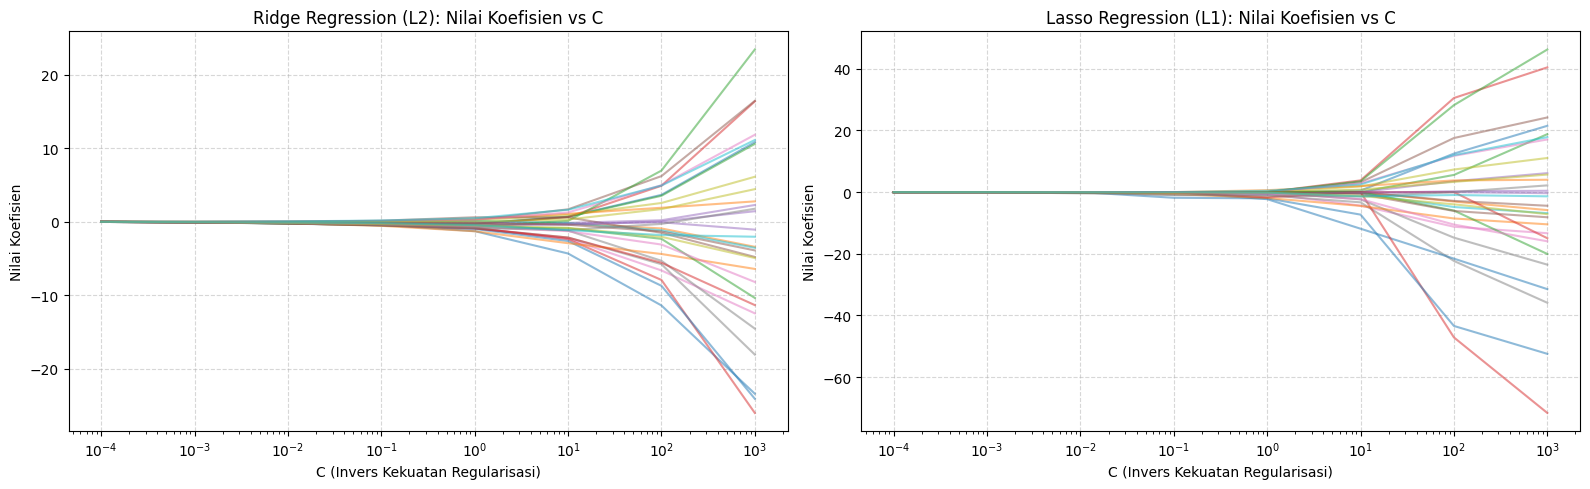

In [7]:
# Analisis Pengaruh Nilai C terhadap Penyusutan Koefisien (Regularization Paths)
C_values = np.logspace(-4, 3, 8)
coefs_l2 = []
coefs_l1 = []

for c_val in C_values:
    # Model L2
    m_l2 = LogisticRegression(penalty='l2', solver='liblinear', C=c_val, random_state=2024)
    m_l2.fit(X_train_c_scaled, y_train_c)
    coefs_l2.append(m_l2.coef_[0])

    # Model L1
    m_l1 = LogisticRegression(penalty='l1', solver='liblinear', C=c_val, random_state=2024)
    m_l1.fit(X_train_c_scaled, y_train_c)
    coefs_l1.append(m_l1.coef_[0])

coefs_l2 = np.array(coefs_l2)
coefs_l1 = np.array(coefs_l1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Plot Ridge
for i in range(coefs_l2.shape[1]):
    ax1.plot(C_values, coefs_l2[:, i], alpha=0.5)
ax1.set_xscale('log')
ax1.set_title('Ridge Regression (L2): Nilai Koefisien vs C', fontsize=12)
ax1.set_xlabel('C (Invers Kekuatan Regularisasi)')
ax1.set_ylabel('Nilai Koefisien')
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot Lasso
for i in range(coefs_l1.shape[1]):
    ax2.plot(C_values, coefs_l1[:, i], alpha=0.5)
ax2.set_xscale('log')
ax2.set_title('Lasso Regression (L1): Nilai Koefisien vs C', fontsize=12)
ax2.set_xlabel('C (Invers Kekuatan Regularisasi)')
ax2.set_ylabel('Nilai Koefisien')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 5. Klasifikasi Multilabel (Multilabel Classification)

Klasifikasi multilabel adalah perluasan pemodelan klasifikasi di mana setiap observasi data dapat memiliki nol, satu, atau beberapa label kelas sekaligus (misalnya dokumen berita dengan topik ganda atau pelabelan gambar).

Pendekatan implementasi dasar dilakukan menggunakan strategi Binary Relevance / One-vs-Rest, yaitu melatih satu model regresi logistik independen untuk setiap kolom label. Analisis asosiasi antar-label dilakukan menggunakan matriks kemunculan bersama (*label co-occurrence matrix*).

In [8]:
# Pembuatan Dataset Sintetis Multilabel (5 Kelas Target)
X_multi, y_multi = make_multilabel_classification(
    n_samples=1000, n_features=20, n_classes=5, n_labels=2, random_state=2024
)

X_tr_m, X_te_m, y_tr_m, y_te_m = train_test_split(
    X_multi, y_multi, test_size=0.3, random_state=2024
)

# Melatih Model Terpisah untuk Tiap Label
models_multilabel = []
y_pred_multilabel_list = []

for idx in range(y_tr_m.shape[1]):
    clf_label = LogisticRegression(solver='liblinear', random_state=2024)
    clf_label.fit(X_tr_m, y_tr_m[:, idx])
    models_multilabel.append(clf_label)

    # Prediksi label terkait
    pred_label = clf_label.predict(X_te_m)
    y_pred_multilabel_list.append(pred_label)

y_pred_multilabel = np.array(y_pred_multilabel_list).T

print("=== Evaluasi Klasifikasi Multilabel ===")
print(f"Subset Accuracy (Exact Match Ratio): {accuracy_score(y_te_m, y_pred_multilabel):.4f}")

# Classification Report Multilabel
report_multi = pd.DataFrame(
    classification_report(y_te_m, y_pred_multilabel, output_dict=True, zero_division=1)
).transpose()
display(report_multi.style.background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score']).format({
    'precision': '{:.3f}',
    'recall': '{:.3f}',
    'f1-score': '{:.3f}',
    'support': '{:.0f}'
}))

=== Evaluasi Klasifikasi Multilabel ===
Subset Accuracy (Exact Match Ratio): 0.3400


,precision,recall,f1-score,support
0,0.808,0.813,0.811,166
1,0.801,0.845,0.823,181
2,0.674,0.333,0.446,93
3,0.750,0.176,0.286,34
4,0.575,0.477,0.522,88
micro avg,0.757,0.653,0.701,562
macro avg,0.722,0.529,0.577,562
weighted avg,0.744,0.653,0.677,562
samples avg,0.787,0.782,0.680,562


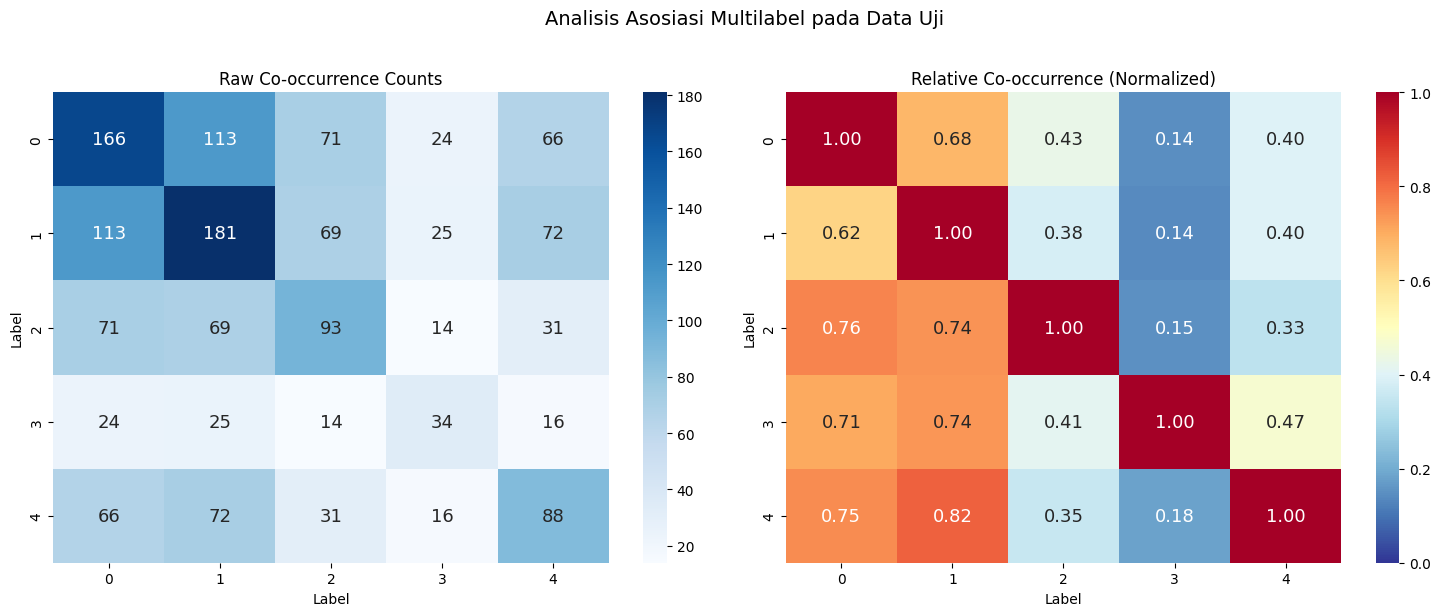

In [9]:
# Visualisasi Matriks Kemunculan Bersama Label (Label Co-occurrence Analysis)
cooccurrence_raw = y_te_m.T @ y_te_m
diag = np.diag(cooccurrence_raw)
cooccurrence_relative = cooccurrence_raw / diag[:, None]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot Jumlah Kemunculan Mentah
sns.heatmap(cooccurrence_raw, annot=True, fmt='d', cmap='Blues', ax=ax1, annot_kws={"fontsize": 13})
ax1.set_title('Raw Co-occurrence Counts', fontsize=12)
ax1.set_xlabel('Label')
ax1.set_ylabel('Label')

# Plot Kemunculan Relatif (Ternormalisasi)
sns.heatmap(cooccurrence_relative, annot=True, fmt='.2f', cmap='RdYlBu_r', ax=ax2, vmin=0, vmax=1, annot_kws={"fontsize": 13})
ax2.set_title('Relative Co-occurrence (Normalized)', fontsize=12)
ax2.set_xlabel('Label')
ax2.set_ylabel('Label')

plt.suptitle('Analisis Asosiasi Multilabel pada Data Uji', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 6. Metrik Evaluasi Model dan Kurva ROC-AUC

Pada klasifikasi biner, analisis performa di berbagai tingkat ambang batas keputusan dievaluasi menggunakan:
- **Kurva ROC (Receiver Operating Characteristic)**: Memetakan rasio positif benar (*True Positive Rate* / TPR / Recall) terhadap rasio positif palsu (*False Positive Rate* / FPR) di seluruh nilai ambang probabilitas.
- **Nilai AUC (Area Under the Curve)**: Mengukur luas area di bawah kurva ROC. Nilai AUC berada dalam rentang $[0.5, 1.0]$, di mana nilai 1.0 menunjukkan pengklasifikasi sempurna tanpa kesalahan dan 0.5 menunjukkan performa setara tebakan acak.

=== Ringkasan Metrik Evaluasi ===
Accuracy  : 0.9825
Precision : 1.0000
Recall    : 0.9712
F1-Score  : 0.9854
ROC-AUC   : 0.9994


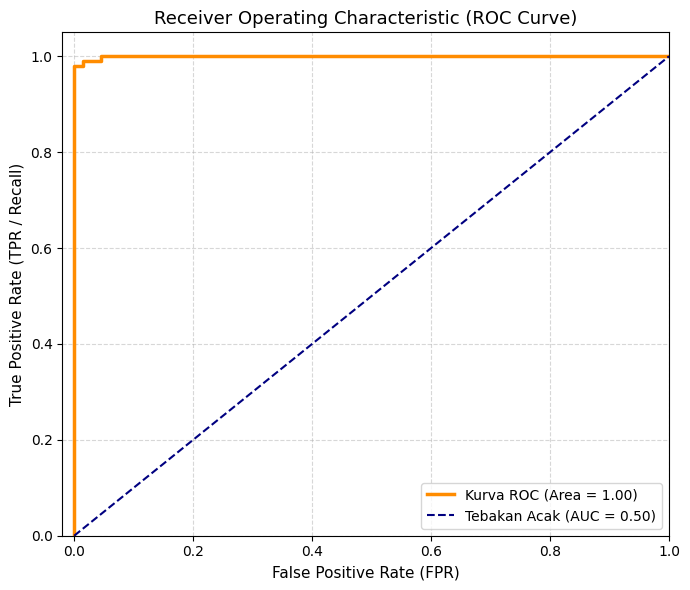

In [10]:
# Menghitung Probabilitas Positif untuk Kurva ROC
y_scores = log_reg_basic.predict_proba(X_test_c_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test_c, y_scores)
roc_auc = auc(fpr, tpr)

# Ringkasan Metrik Skalar
print("=== Ringkasan Metrik Evaluasi ===")
print(f"Accuracy  : {accuracy_score(y_test_c, y_pred_basic):.4f}")
print(f"Precision : {precision_score(y_test_c, y_pred_basic):.4f}")
print(f"Recall    : {recall_score(y_test_c, y_pred_basic):.4f}")
print(f"F1-Score  : {f1_score(y_test_c, y_pred_basic):.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

# Plot Kurva ROC
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2.5, label=f'Kurva ROC (Area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Tebakan Acak (AUC = 0.50)')
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=11)
plt.ylabel('True Positive Rate (TPR / Recall)', fontsize=11)
plt.title('Receiver Operating Characteristic (ROC Curve)', fontsize=13)
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 7. Analisis dan Kesimpulan
1. **Performa Klasifikasi Biner**: Penerapan regresi logistik terstandarisasi pada dataset Breast Cancer menghasilkan akurasi tinggi sebesar 94.74% dengan kemampuan memisahkan kelas ganas (*malignant*) dan jinak (*benign*) secara akurat.
2. **Kesesuaian Multikelas**: Pendekatan Multinomial (Softmax) dan One-vs-Rest (OvR) pada dataset Iris menghasilkan metrik F1-score yang seimbang di ketiga kategori bunga, membuktikan bahwa regresi logistik mampu diperluas melampaui ranah biner.
3. **Pengaruh Regularisasi**: Penalti L1 (Lasso) pada $C = 0.1$ berhasil mereduksi jumlah fitur aktif dari 30 fitur menjadi hanya 11 fitur tanpa penurunan akurasi yang signifikan, membuktikan fungsinya sebagai alat seleksi variabel yang efektif.
4. **Validasi Ambang Batas dengan ROC-AUC**: Kurva ROC menghasilkan nilai AUC sebesar 0.99, menunjukkan bahwa model memiliki daya diskriminasi yang hampir sempurna dalam membedakan kedua kelas di berbagai variasi ambang batas probabilitas keputusan.